In [1]:
import os
import re
import pickle
import argparse
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import json
from PIL import Image
import matplotlib.pyplot as plt

import geopandas as gpd
from shapely.ops import transform

def normalize_gdf_linestrings(gdf: gpd.GeoDataFrame,
                             bbox: tuple[float, float, float, float],
                             geometry_col: str = "geometry",
                             inplace: bool = False) -> gpd.GeoDataFrame:
    """
    Normalize lon/lat coordinates inside LineString/MultiLineString geometries
    into [0,1]x[0,1] using bbox = (min_lon, max_lon, min_lat, max_lat).

    Note: values outside bbox will be <0 or >1 unless you clamp (see clamp option below).
    """
    min_lon, max_lon, min_lat, max_lat = bbox

    dx = max_lon - min_lon
    dy = max_lat - min_lat
    if dx == 0 or dy == 0:
        raise ValueError("Invalid bbox: max_lon==min_lon or max_lat==min_lat")

    def _norm_xy(x, y, z=None):
        xn = (x - min_lon) / dx
        yn = (y - min_lat) / dy
        return (xn, yn) if z is None else (xn, yn, z)

    out = gdf if inplace else gdf.copy()
    out[geometry_col] = out[geometry_col].apply(
        lambda geom: transform(_norm_xy, geom) if geom is not None else None
    )
    return out

def crop_image(img_arr, center, crop_size=0.5, output_size=(256, 256)):
    """
    Crops image (H, W, C) around center (x, y). 
    Assumes img_arr is SQUARE (H=W) to maintain aspect ratio consistency.
    """
    H, W = img_arr.shape[:2]
    cx_norm, cy_norm = center
    
    # 1. Convert Center to Pixels (WITH Y-INVERSION)
    # Geospatial (0,0) is Bottom-Left. Image (0,0) is Top-Left.
    px_cx = int(cx_norm * W)
    px_cy = int((1 - cy_norm) * H)
    
    # 2. Calculate Radius (half of the crop window)
    # Since W=H, this covers the same normalized distance in X and Y.
    # crop_size 0.5 -> covers 0.5 normalized units (0.25 radius).
    # This guarantees 'dist_max=0.2' is visible.
    px_half = int((crop_size * W) / 2)
    
    x1, y1 = px_cx - px_half, px_cy - px_half
    x2, y2 = px_cx + px_half, px_cy + px_half
    
    # 3. Padding Logic (Handle boundaries)
    pad_l, pad_t = max(0, -x1), max(0, -y1)
    pad_r, pad_b = max(0, x2 - W), max(0, y2 - H)
    
    x1_v, y1_v = max(0, x1), max(0, y1)
    x2_v, y2_v = min(W, x2), min(H, y2)
    
    valid_crop = img_arr[y1_v:y2_v, x1_v:x2_v]
    
    if pad_l > 0 or pad_t > 0 or pad_r > 0 or pad_b > 0:
        pads = ((pad_t, pad_b), (pad_l, pad_r))
        if len(img_arr.shape) == 3: 
            pads += ((0, 0),) 
        valid_crop = np.pad(valid_crop, pads, mode='constant', constant_values=0)
            
    return cv2.resize(valid_crop, output_size, interpolation=cv2.INTER_LINEAR)

In [2]:
split_path = "/data/aiclinic/pathways/generation_full_data/test.txt"
with open(split_path, "r") as f:
    split_indices = [line.strip() for line in f if line.strip()]

In [4]:
idx = split_indices[2]
img = Image.open(f'/data/aiclinic/pathways/generation_full_data/pairs/{idx}/satellite.png')
with open(f'/data/aiclinic/pathways/generation_full_data/pairs/{idx}/bbox.json', 'r') as f:
    bbox = json.load(f)['bbox']
graph =  gpd.read_file(f"/data/models/bin/2026_pathway_generation/predictions/tile2net/base/seed_0/{idx}_seed0_gt.geojson")
gdf_norm = normalize_gdf_linestrings(graph, bbox)
bbox_norm = [0,1,0,1]

### Iterative Generation

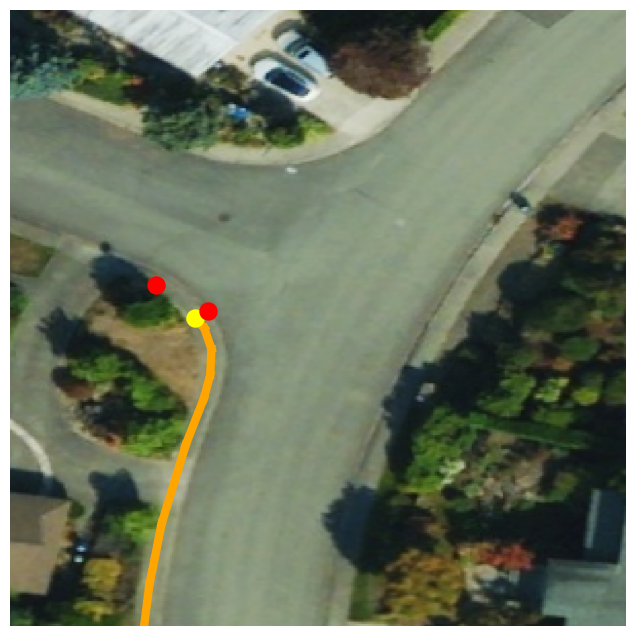

In [87]:
point_size = 150
lw = 6.0
z = 3
point_color = "yellow"
neighbor_color = "red"
line_color = "orange"
min_lon, max_lon, min_lat, max_lat = bbox_norm
cx = 0.36519999999374153
cy = 0.4614000000000213
zoom_bbox = (cx-0.15, cx+0.35, cy-0.25, cy+0.25)

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(zoom_bbox[0], zoom_bbox[1])
ax.set_ylim(zoom_bbox[2], zoom_bbox[3])
ax.axis("off")
ax.imshow(img, extent=bbox_norm)

## state
x,y = gdf_norm.geometry.values[23].coords.xy
ax.scatter(x[0], y[0], color=point_color, s=point_size, zorder=z)
for geom in gdf_norm.geometry.values[12:23]:
    x, y = geom.xy
    ax.plot(x, y, color=line_color, linewidth=lw)
    
## neighbors
x,y = gdf_norm.geometry.values[25].coords.xy
ax.scatter(x[1], y[1], color=neighbor_color, s=point_size, zorder=z)
x,y = gdf_norm.geometry.values[27].coords.xy
ax.scatter(x[0], y[0], color=neighbor_color, s=point_size, zorder=z)
plt.savefig("../evaluation/visualizations/iterative_1.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
pass

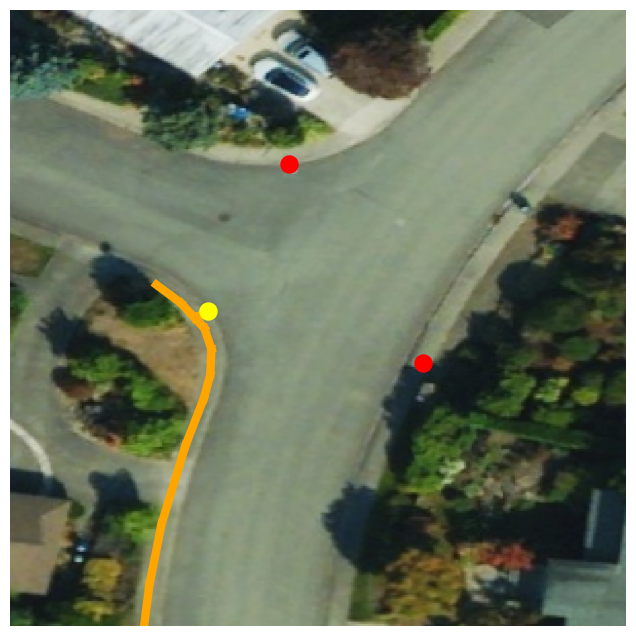

In [93]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(zoom_bbox[0], zoom_bbox[1])
ax.set_ylim(zoom_bbox[2], zoom_bbox[3])
ax.axis("off")
ax.imshow(img, extent=bbox_norm)

## state
x,y = gdf_norm.geometry.values[27].coords.xy
ax.scatter(x[0], y[0], color=point_color, s=point_size, zorder=z)
for geom in gdf_norm.geometry.values[12:26]:
    x, y = geom.xy
    ax.plot(x, y, color=line_color, linewidth=lw)
for geom in gdf_norm.geometry.values[28:29]:
    x, y = geom.xy
    ax.plot(x, y, color=line_color, linewidth=lw)

## neighbors
x,y = gdf_norm.geometry.values[30].coords.xy
ax.scatter(x[0], y[0], color=neighbor_color, s=point_size, zorder=z)
x,y = gdf_norm.geometry.values[44].coords.xy
ax.scatter(x[1], y[1], color=neighbor_color, s=point_size, zorder=z)
plt.savefig("../evaluation/visualizations/iterative_2.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
pass

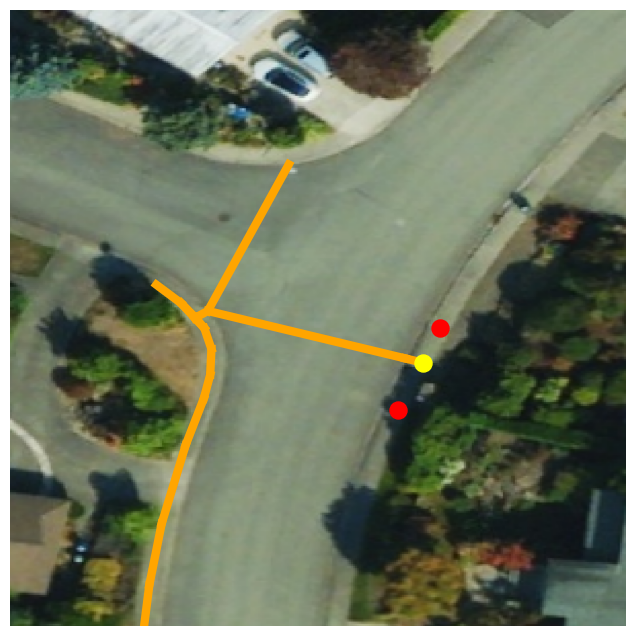

In [94]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(zoom_bbox[0], zoom_bbox[1])
ax.set_ylim(zoom_bbox[2], zoom_bbox[3])
ax.axis("off")
ax.imshow(img, extent=bbox_norm)

## state
x,y = gdf_norm.geometry.values[44].coords.xy
ax.scatter(x[1], y[1], color=point_color, s=point_size, zorder=z)
for geom in gdf_norm.geometry.values[12:30]:
    x, y = geom.xy
    ax.plot(x, y, color=line_color, linewidth=lw)
for geom in gdf_norm.geometry.values[43:44]:
    x, y = geom.xy
    ax.plot(x, y, color=line_color, linewidth=lw)

## neighbors
x,y = gdf_norm.geometry.values[41].coords.xy
ax.scatter(x[0], y[0], color=neighbor_color, s=point_size, zorder=z)
x,y = gdf_norm.geometry.values[42].coords.xy
ax.scatter(x[1], y[1], color=neighbor_color, s=point_size, zorder=z)
plt.savefig("../evaluation/visualizations/iterative_3.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
pass

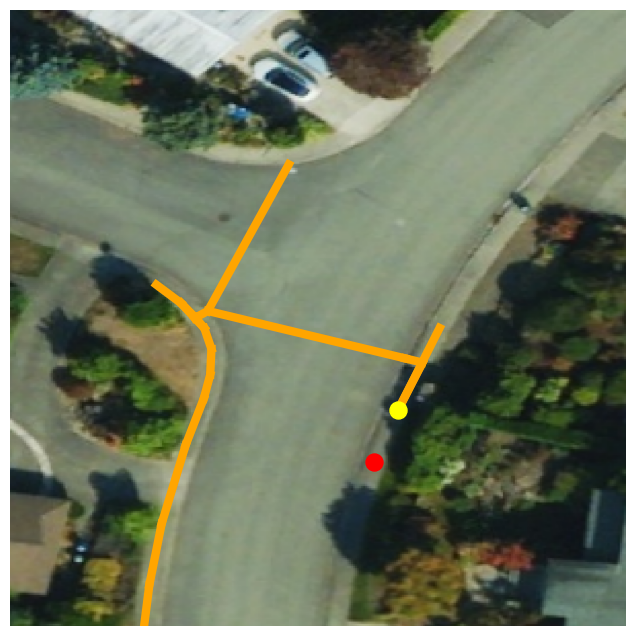

In [95]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(zoom_bbox[0], zoom_bbox[1])
ax.set_ylim(zoom_bbox[2], zoom_bbox[3])
ax.axis("off")
ax.imshow(img, extent=bbox_norm)

## state
x,y = gdf_norm.geometry.values[41].coords.xy
ax.scatter(x[0], y[0], color=point_color, s=point_size, zorder=z)
for geom in gdf_norm.geometry.values[12:30]:
    x, y = geom.xy
    ax.plot(x, y, color=line_color, linewidth=lw)
for geom in gdf_norm.geometry.values[40:44]:
    x, y = geom.xy
    ax.plot(x, y, color=line_color, linewidth=lw)

## neighbors
x,y = gdf_norm.geometry.values[39].coords.xy
ax.scatter(x[0], y[0], color=neighbor_color, s=point_size, zorder=z)
plt.savefig("../evaluation/visualizations/iterative_4.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
pass

### Canvas

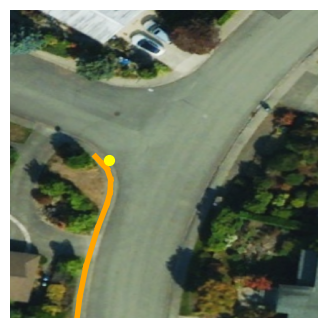

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.set_xlim(zoom_bbox[0], zoom_bbox[1])
ax.set_ylim(zoom_bbox[2], zoom_bbox[3])
ax.axis("off")
ax.imshow(img, extent=bbox_norm)

## state
x,y = gdf_norm.geometry.values[27].coords.xy
ax.scatter(x[0], y[0], color=point_color, s=point_size, zorder=z)
for geom in gdf_norm.geometry.values[11:24]:
    x, y = geom.xy
    ax.plot(x, y, color=line_color, linewidth=lw)
# plt.savefig("../evaluation/visualizations/traversCNN_global.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
pass

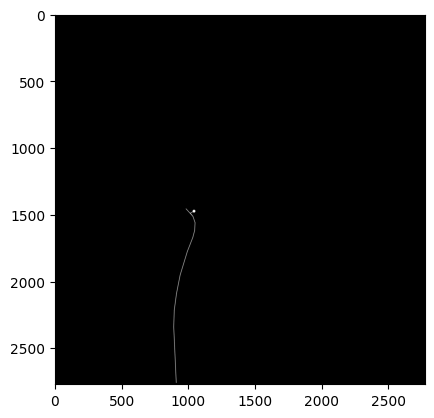

In [121]:
import cv2
H, W = img.size
global_canvas = np.zeros((H, W), dtype=np.uint8)
x,y = gdf_norm.geometry[27].xy
u_pos = (x[0], y[0])
px_u = (int(u_pos[0] * W), int((1 - u_pos[1]) * H))
cv2.circle(global_canvas, px_u, radius=10, color=255, thickness=-1, lineType=cv2.LINE_AA)
for geom in gdf_norm.geometry.values[12:24]:
    x, y = geom.xy
    px_u = (int(x[0] * W), int((1 - y[0]) * H))
    px_v = (int(x[1] * W), int((1 - y[1]) * H))
    cv2.line(global_canvas, px_u, px_v, color=255, thickness=2, lineType=cv2.LINE_AA)
for geom in gdf_norm.geometry.values[28:29]:
    x, y = geom.xy
    px_u = (int(x[0] * W), int((1 - y[0]) * H))
    px_v = (int(x[1] * W), int((1 - y[1]) * H))
    cv2.line(global_canvas, px_u, px_v, color=255, thickness=2, lineType=cv2.LINE_AA)
plt.imshow(global_canvas, cmap="gray")
pass

In [126]:
img_bgr = cv2.imread(f'/data/aiclinic/pathways/generation_full_data/pairs/{idx}/satellite.png', cv2.IMREAD_COLOR)
satellite_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
sat_crop = crop_image(satellite_img, u_pos, 0.5, (256,256))
can_crop = crop_image(global_canvas, u_pos, 0.5, (256,256))

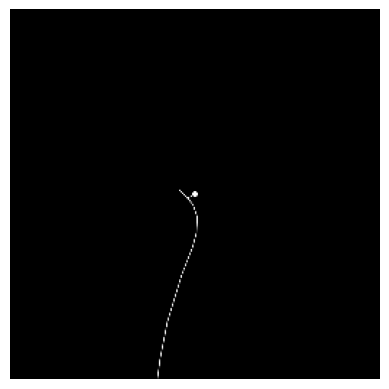

In [139]:
plt.imshow(can_crop, cmap="gray")
plt.axis("off")
plt.savefig("../evaluation/visualizations/traversCNN_canvas.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
pass

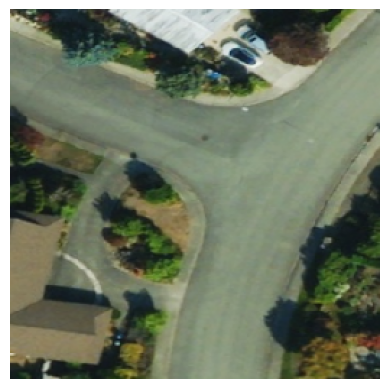

In [140]:
plt.imshow(sat_crop)
plt.axis("off")
plt.savefig("../evaluation/visualizations/traversCNN_local.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
pass

### TraversRL

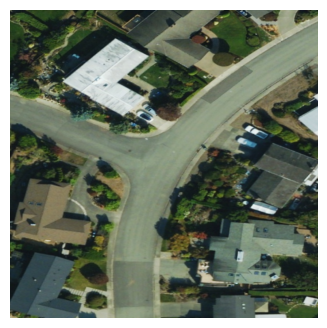

In [146]:
min_lon, max_lon, min_lat, max_lat = bbox
fig, ax = plt.subplots(figsize=(4, 4))
ax.set_xlim(min_lon, max_lon)
ax.set_ylim(min_lat, max_lat)
ax.axis("off")
ax.imshow(img, extent=bbox)
plt.savefig("../evaluation/visualizations/traversRL_global.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
pass

In [157]:
pred1 =  gpd.read_file(f"/data/models/bin/2026_pathway_generation/predictions/resnet18/base/seed_0/{idx}_seed0_pred.geojson")
pred2 =  gpd.read_file(f"/data/models/bin/2026_pathway_generation/predictions/resnet18/base/seed_1/{idx}_seed1_pred.geojson")
pred3 =  gpd.read_file(f"/data/models/bin/2026_pathway_generation/predictions/resnet18/base/seed_2/{idx}_seed2_pred.geojson")
pred4 =  gpd.read_file(f"/data/models/bin/2026_pathway_generation/predictions/resnet18/base/seed_3/{idx}_seed3_pred.geojson")

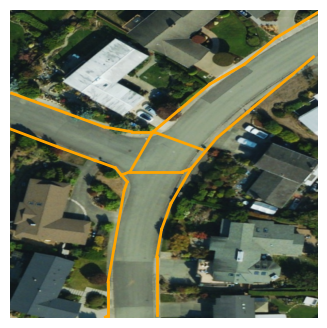

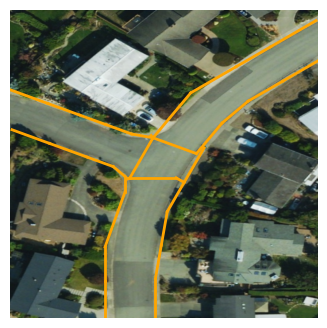

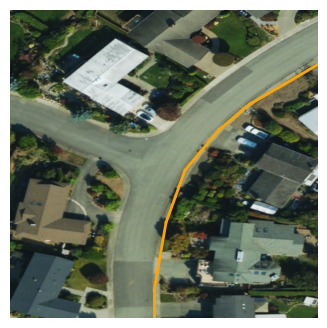

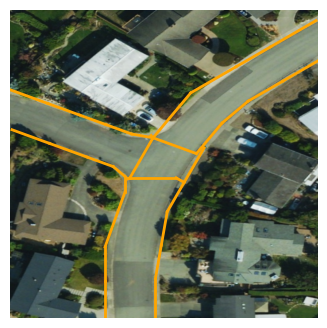

In [164]:
for i, pred in enumerate([pred1, pred2, pred3, pred4]):
    min_lon, max_lon, min_lat, max_lat = bbox
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_xlim(min_lon, max_lon)
    ax.set_ylim(min_lat, max_lat)
    ax.axis("off")
    ax.imshow(img, extent=bbox)
    for geom in pred.geometry:
        x, y = geom.xy
        ax.plot(x, y, color=line_color, linewidth=2)
    plt.savefig(f"../evaluation/visualizations/traversRL_pred{i}.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
    pass